# MC-IA-NAN: Monotonicity-Constrained Interaction-Aware Neural Additive Network
## Five-year subsequent-primary-malignancy prediction — executed research implementation

**Input:** the provided `seer final dataset(1).csv` only. **No synthetic rows, augmentation, or fabricated metrics.** The supplied CSV is used as received; this notebook does not verify its registry provenance. No conventional statistical/ML/DNN baseline models are trained, by request. Instead, the proposed architecture is tested with its own component ablations.

**Important:** This is a methodological implementation, **not** a clinically validated risk model and **not** evidence that radiotherapy caused a subsequent cancer. The five-year endpoint and treatment coding are accepted as supplied. We explicitly exclude follow-up and subsequent-diagnosis fields from predictors. Some retrospective treatment variables can still introduce temporal leakage if they were unknown at the prediction baseline; interpret the results accordingly.

Research structure: cohort audit → EDA → leakage-safe predictors → 70/15/15 split → NAM / constrained NAM / interaction-aware MC-IA-NAN ablations → MC dropout → temperature calibration → comprehensive evaluation and explanations.


In [1]:
import os, warnings, random, copy, math, json
from pathlib import Path
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, precision_recall_curve, brier_score_loss, log_loss)
from scipy.special import expit, logit
from scipy.optimize import minimize_scalar
from sklearn.calibration import calibration_curve
warnings.filterwarnings('ignore', category=FutureWarning)
SEED=42
np.random.seed(SEED);random.seed(SEED);torch.manual_seed(SEED)
torch.set_num_threads(min(4,os.cpu_count() or 2))
sns.set_theme(style='whitegrid',context='notebook',palette='deep')
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':160,'axes.titlesize':12,'axes.labelsize':10,'xtick.labelsize':9,'ytick.labelsize':9})
OUT=Path('mc_ia_nan_outputs');OUT.mkdir(exist_ok=True)
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
print('PyTorch:',torch.__version__,'Device:',DEVICE)
def savefig(name):
    plt.tight_layout();plt.savefig(OUT/name,bbox_inches='tight');plt.show();plt.close()
def tidy_x(ax, long=False):
    ax.tick_params(axis='x',labelrotation=90 if long else 0)


PyTorch: 2.10.0+cpu Device: cpu


## 1. Read and audit the exact supplied dataset

In [2]:
candidates=[Path('seer final dataset(1).csv'),Path('/mnt/data/seer final dataset(1).csv')]
CSV_PATH=next((x for x in candidates if x.exists()),None)
if CSV_PATH is None:raise FileNotFoundError('Place seer final dataset(1).csv beside this notebook.')
df=pd.read_csv(CSV_PATH,low_memory=False)
TARGET='Subsequent primary malignancy within 5 years'
assert TARGET in df and set(df[TARGET].dropna().unique()).issubset({0,1})
print('Loaded:',CSV_PATH,' | Shape:',df.shape,' | Target counts:',df[TARGET].value_counts())
display(df.head(3));display(pd.DataFrame({'type':df.dtypes.astype(str),'missing':df.isna().sum(),'unique':df.nunique()}))
print('Duplicate patient IDs:',df['Patient ID'].duplicated().sum())
print('Censoring flags:',df[['Right censored before 5 years','Competing death before 5 years','Five-year classification outcome available']].apply(lambda x:x.value_counts()).fillna(0).to_string())


Loaded: seer final dataset(1).csv  | Shape: (44336, 31)  | Target counts: Subsequent primary malignancy within 5 years
0    41152
1     3184
Name: count, dtype: int64


,Patient ID,Age at primary diagnosis,Sex,"Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)",Primary Site,Histologic Type ICD-O-3,Behavior code ICD-O-3,Combined Summary Stage with Expanded Regional Codes (2004+),Grade Recode (thru 2017),Derived Summary Grade 2018 (2018+),Radiation recode,RX Summ--Surg/Rad Seq,RX Summ--Surg Prim Site (1998-2022),"Chemotherapy recode (yes, no/unk)",Year of diagnosis,Month of diagnosis,Time from diagnosis to treatment in days recode,Prediction baseline,Prediction horizon (months),Subsequent primary malignancy within 5 years,Subsequent primary diagnosis date,Subsequent primary site,Months to subsequent primary,Observed follow-up months,End of observation date,Event observed,Right censored before 5 years,Competing death before 5 years,Five-year classification outcome available,Vital status recode (study cutoff used),Follow-up endpoint type
0,ID0000001,67,Male,Non-Hispanic White,C61.9,8140/3,3,Localized,Grade II,Not applicable (before 2018),Beam radiation,Radiation after surgery,Surgery performed,No/Unknown,2008,9,44,2008-09-07,60,0,Not applicable,Not applicable,Not applicable,60,2013-09-07,0,0,0,1,Alive,Completed five-year follow-up
1,ID0000002,62,Female,Non-Hispanic White,C50.9,8500/3,3,Regional,Grade II,Not applicable (before 2018),Beam radiation,Radiation before surgery,Surgery performed,Yes,2017,12,134,2017-12-02,60,0,Not applicable,Not applicable,Not applicable,60,2022-12-02,0,0,0,1,Alive,Completed five-year follow-up
2,ID0000003,76,Female,Non-Hispanic White,C50.9,8500/3,3,Localized,Grade III,Not applicable (before 2018),Beam radiation,Radiation after surgery,Surgery performed,Yes,2010,3,34,2010-03-04,60,0,Not applicable,Not applicable,Not applicable,60,2015-03-04,0,0,0,1,Alive,Completed five-year follow-up


,type,missing,unique
Patient ID,object,0,44336
Age at primary diagnosis,int64,0,67
Sex,object,0,2
"Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)",object,0,5
Primary Site,object,0,10
Histologic Type ICD-O-3,object,0,6
Behavior code ICD-O-3,int64,0,1
Combined Summary Stage with Expanded Regional Codes (2004+),object,0,4
Grade Recode (thru 2017),object,0,6
Derived Summary Grade 2018 (2018+),object,0,6


Duplicate patient IDs: 0
Censoring flags:    Right censored before 5 years  Competing death before 5 years  Five-year classification outcome available
0                        44336.0                         44336.0                                         0.0
1                            0.0                             0.0                                     44336.0


### Leakage-control policy
Exclude identifiers, target-derived endpoints, events, follow-up length, outcome availability, study-cutoff vital status, all future malignancy details, prediction-baseline date, and constant fields. Histology and primary site can be highly redundant; both remain available for interpretability, but associations may reflect constructed cohort patterns. Diagnosis-year and treatment indicators are used as recorded, conditional on their availability by the *intended* prediction time. The supplied CSV cannot independently establish clinical timing.

In [3]:
EXCLUDE=['Patient ID',TARGET,'Behavior code ICD-O-3','Prediction baseline','Prediction horizon (months)',
'Subsequent primary diagnosis date','Subsequent primary site','Months to subsequent primary','Observed follow-up months',
'End of observation date','Event observed','Right censored before 5 years','Competing death before 5 years',
'Five-year classification outcome available','Vital status recode (study cutoff used)','Follow-up endpoint type']
PREDICTORS=[c for c in df.columns if c not in EXCLUDE]
NUM_COLS=['Age at primary diagnosis','Year of diagnosis','Month of diagnosis','Time from diagnosis to treatment in days recode']
CAT_COLS=[c for c in PREDICTORS if c not in NUM_COLS]
print('Predictors:',len(PREDICTORS),' | Numeric:',NUM_COLS,' | Categorical:',CAT_COLS)
print('Constant among selected:',[c for c in PREDICTORS if df[c].nunique()==1])
assert not set(PREDICTORS)&set(EXCLUDE)


Predictors: 15  | Numeric: ['Age at primary diagnosis', 'Year of diagnosis', 'Month of diagnosis', 'Time from diagnosis to treatment in days recode']  | Categorical: ['Sex', 'Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)', 'Primary Site', 'Histologic Type ICD-O-3', 'Combined Summary Stage with Expanded Regional Codes (2004+)', 'Grade Recode (thru 2017)', 'Derived Summary Grade 2018 (2018+)', 'Radiation recode', 'RX Summ--Surg/Rad Seq', 'RX Summ--Surg Prim Site (1998-2022)', 'Chemotherapy recode (yes, no/unk)']
Constant among selected: []


## 2. Descriptive analysis and Seaborn figures

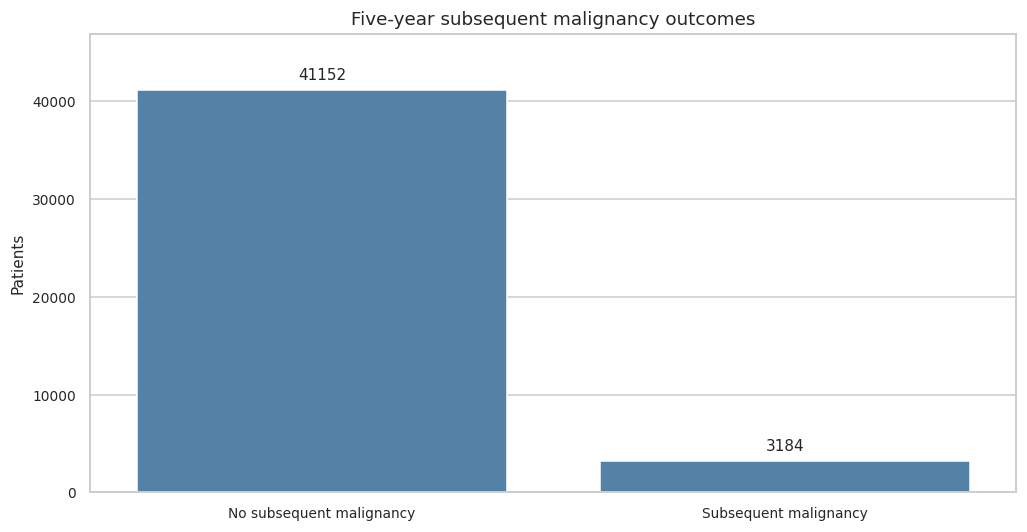

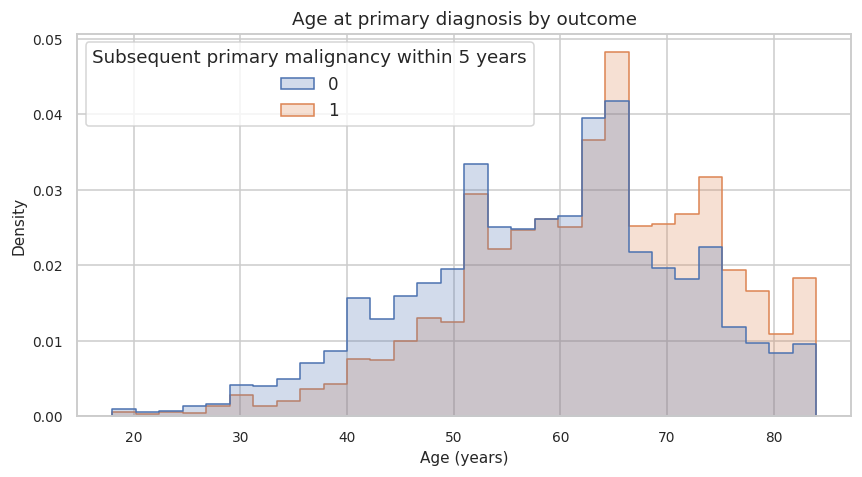

In [4]:
fig,ax=plt.subplots(figsize=(9.5,5.0))
v=df[TARGET].map({0:'No subsequent malignancy',1:'Subsequent malignancy'})
sns.countplot(x=v,ax=ax,order=['No subsequent malignancy','Subsequent malignancy'],color='steelblue')
ax.set(xlabel='',ylabel='Patients',title='Five-year subsequent malignancy outcomes')
ax.tick_params(axis='x',labelrotation=0)
ax.set_ylim(0,df[TARGET].value_counts().max()*1.14)
for container in ax.containers:ax.bar_label(container,fmt='%d',padding=5,fontsize=10)
savefig('01_target_distribution.png')
fig,ax=plt.subplots(figsize=(8,4.5));sns.histplot(data=df,x='Age at primary diagnosis',hue=TARGET,stat='density',common_norm=False,bins=30,element='step',alpha=.25,ax=ax);ax.set(title='Age at primary diagnosis by outcome',xlabel='Age (years)');savefig('02_age_distribution.png')

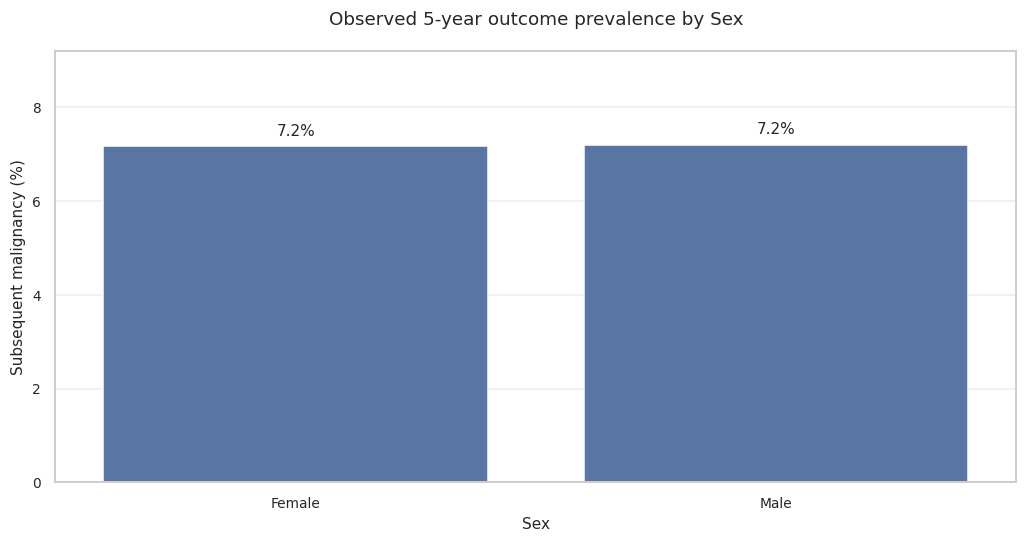

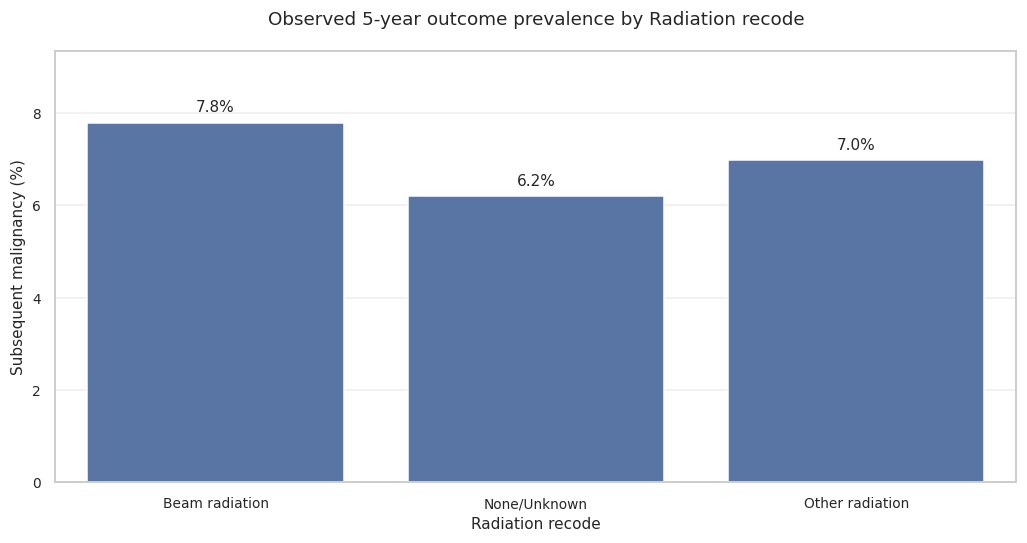

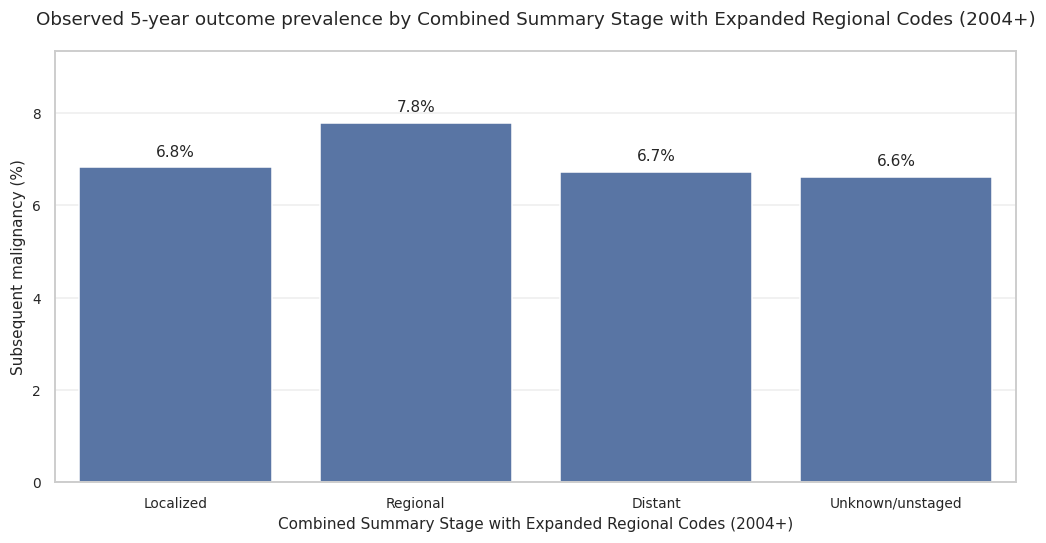

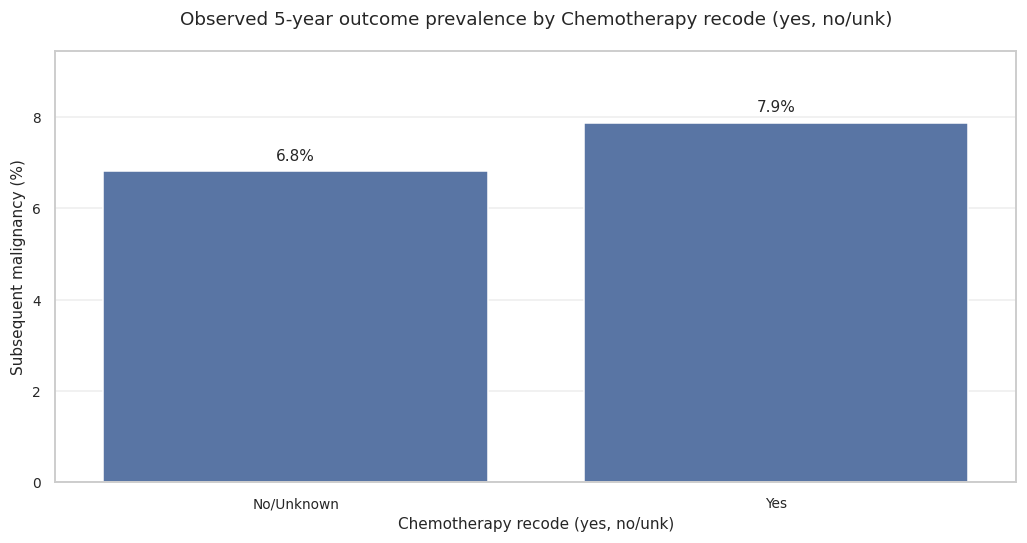

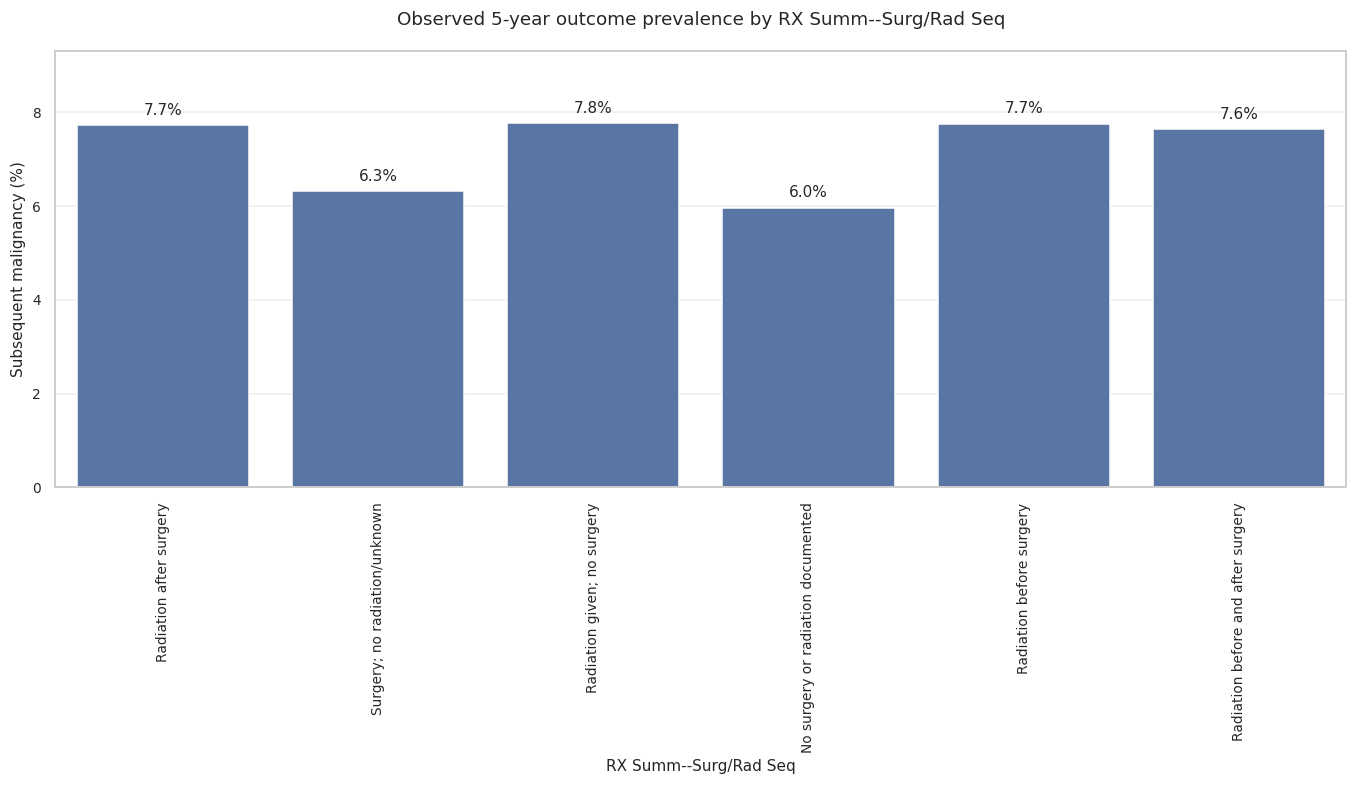

In [5]:
for col,tag in [('Sex','sex'),('Radiation recode','radiation'),('Combined Summary Stage with Expanded Regional Codes (2004+)','stage'),('Chemotherapy recode (yes, no/unk)','chemotherapy'),('RX Summ--Surg/Rad Seq','sequence')]:
    tab=df.groupby(col)[TARGET].agg(['mean','size']).sort_values('size',ascending=False)
    values=tab['mean']*100
    is_sequence=(tag=='sequence')
    fig_width=12.5 if is_sequence else max(9.5,min(13.5,len(tab)*2.1))
    fig_height=7.3 if is_sequence else 5.1
    fig,ax=plt.subplots(figsize=(fig_width,fig_height))
    sns.barplot(x=tab.index,y=values,ax=ax,color=sns.color_palette()[0])
    ax.set(title=f'Observed 5-year outcome prevalence by {col}',xlabel=col,ylabel='Subsequent malignancy (%)')
    # Keep labels at 0 degrees unless full labels would overlap.
    ax.tick_params(axis='x',labelrotation=90 if is_sequence else 0)
    if not is_sequence:
        for label in ax.get_xticklabels():label.set_ha('center')
    ax.set_ylim(0,max(9.2,float(values.max())*1.2))
    ax.set_title(f'Observed 5-year outcome prevalence by {col}',pad=17,fontsize=12)
    ax.yaxis.grid(True,alpha=.35)
    for i,val in enumerate(values):ax.annotate(f'{val:.1f}%',(i,val),xytext=(0,5),textcoords='offset points',ha='center',va='bottom',fontsize=10)
    if is_sequence:
        fig.subplots_adjust(bottom=.38,top=.89,left=.09,right=.97)
    else:
        fig.subplots_adjust(bottom=.18,top=.87,left=.10,right=.97)
    savefig(f'03_{tag}_prevalence.png')

## 3. Split first; fit encoders and scalers on training only

In [7]:
y=df[TARGET].to_numpy(dtype=np.int64)
all_idx=np.arange(len(df))
train_idx,hold_idx=train_test_split(all_idx,test_size=.30,random_state=SEED,stratify=y)
val_idx,test_idx=train_test_split(hold_idx,test_size=.50,random_state=SEED,stratify=y[hold_idx])
tune_idx,cal_idx=train_test_split(val_idx,test_size=.50,random_state=SEED,stratify=y[val_idx])
print('Train / validation / test:',len(train_idx),len(val_idx),len(test_idx))
print('Validation subdivided for early stopping and calibration:',len(tune_idx),len(cal_idx))
for name,ids in [('train',train_idx),('tune',tune_idx),('calibration',cal_idx),('test',test_idx)]:print(name, 'positive prevalence:',round(y[ids].mean(),4))
# convert numeric strings; a missing/unknown indicator is represented by -1 before scaling
xnum=df[NUM_COLS].apply(pd.to_numeric,errors='coerce')
medians=xnum.iloc[train_idx].median();num_filled=xnum.fillna(medians)
scaler=MinMaxScaler().fit(num_filled.iloc[train_idx]);Xn=scaler.transform(num_filled).astype('float32')
# preserve missing indicators for numeric fields when needed: this input is descriptive only here
category_maps={};Xc=[]
for col in CAT_COLS:
    series=df[col].fillna('Missing').astype(str)
    vocab={v:i+1 for i,v in enumerate(sorted(series.iloc[train_idx].unique()))}
    category_maps[col]=vocab
    Xc.append(series.map(vocab).fillna(0).astype('int64').to_numpy())
Xc=np.column_stack(Xc).astype('int64')
print('Network input sizes:',Xn.shape,Xc.shape,' | Categorical levels:',{k:len(v) for k,v in category_maps.items()})


Train / validation / test: 31035 6650 6651
Validation subdivided for early stopping and calibration: 3325 3325
train positive prevalence: 0.0718
tune positive prevalence: 0.0716
calibration positive prevalence: 0.0719
test positive prevalence: 0.0719
Network input sizes: (44336, 4) (44336, 11)  | Categorical levels: {'Sex': 2, 'Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)': 5, 'Primary Site': 10, 'Histologic Type ICD-O-3': 6, 'Combined Summary Stage with Expanded Regional Codes (2004+)': 4, 'Grade Recode (thru 2017)': 6, 'Derived Summary Grade 2018 (2018+)': 6, 'Radiation recode': 3, 'RX Summ--Surg/Rad Seq': 6, 'RX Summ--Surg Prim Site (1998-2022)': 3, 'Chemotherapy recode (yes, no/unk)': 2}


## 4. Proposed network: additive feature subnetworks, monotone feature, sparse interactions
Each numerical input has an independent nonlinear subnetwork; categorical inputs use independent learnable level-contribution embeddings, retaining category-level interpretability. Sparse two-feature interaction subnetworks use compact embeddings and MLPs. An increasing-age monotonic contribution is a **modeling hypothesis for sensitivity analysis**, *not an established medical law*. Interactions deliberately exclude age, so the full risk score is nondecreasing in age when other features are fixed. This restriction may be clinically inappropriate; interpret the monotone ablation as a hypothesis test, not a prescription.

The probability is `sigmoid(bias + sum of feature functions + lambda × sum of interaction functions)`. Weighted BCE is optimized with early stopping and L1 regularization on interaction amplitudes. Temperature scaling is fit only on the calibration partition.

## 5. Train model-component ablations (no external baseline models)

In [9]:
# Fast reproducible CPU defaults; increase MAX_EPOCHS for a longer exploratory optimization.
MAX_EPOCHS=7;PATIENCE=3;BATCH_SIZE=1024;LEARNING_RATE=0.003
POS_WEIGHT=float(len(train_idx)-y[train_idx].sum())/float(y[train_idx].sum())
print('Positive class loss weight:',round(POS_WEIGHT,2))
def collect(model,ids,batch=2048,details=False):
    model.eval();outs=[];fs=[];hs=[]
    with torch.no_grad():
        for xn,xc,_ in loader(ids,batch=batch):
            if details:
                z,f,h=model(xn.to(DEVICE),xc.to(DEVICE),True);fs.append(f.cpu().numpy());hs.append(h.cpu().numpy())
            else:z=model(xn.to(DEVICE),xc.to(DEVICE))
            outs.append(z.cpu().numpy())
    if details:return np.concatenate(outs),np.concatenate(fs),np.concatenate(hs)
    return np.concatenate(outs)
def train_model(title,constrained,interactions):
    torch.manual_seed(SEED)
    model=MCIANAN(constrained,interactions).to(DEVICE)
    opt=torch.optim.Adam(model.parameters(),lr=LEARNING_RATE,weight_decay=1e-5)
    criterion=nn.BCEWithLogitsLoss(pos_weight=torch.tensor(POS_WEIGHT,device=DEVICE))
    history=[];best=np.inf;best_state=None;bad=0
    for epoch in range(MAX_EPOCHS):
        model.train();total=0.;n=0
        for xn,xc,yy in loader(train_idx,BATCH_SIZE,True):
            xn,xc,yy=xn.to(DEVICE),xc.to(DEVICE),yy.to(DEVICE)
            opt.zero_grad();logits,_,hs=model(xn,xc,True)
            loss=criterion(logits,yy)+(0.002*hs.abs().mean() if hs.shape[1] else 0)
            loss.backward();opt.step();total+=float(loss.detach())*len(yy);n+=len(yy)
        model.eval();val_logits=collect(model,tune_idx)
        val_loss=float(nn.functional.binary_cross_entropy_with_logits(torch.from_numpy(val_logits),torch.from_numpy(y[tune_idx].astype('float32')),pos_weight=torch.tensor(POS_WEIGHT)))
        history.append((epoch+1,total/n,val_loss))
        if val_loss<best-1e-4:best=val_loss;best_state=copy.deepcopy(model.state_dict());bad=0
        else:bad+=1
        if bad>=PATIENCE:break
    model.load_state_dict(best_state)
    print(f'{title}: {len(history)} epochs, best tuning loss {best:.4f}')
    return model,pd.DataFrame(history,columns=['epoch','train_weighted_loss','tune_weighted_loss'])
models={};histories={}
for title,constrained,interactions in [('NAM',False,False),('Monotonic NAM',True,False),('Interaction NAM',False,True),('MC-IA-NAN',True,True)]:
    models[title],histories[title]=train_model(title,constrained,interactions)


Positive class loss weight: 12.92


NAM: 7 epochs, best tuning loss 1.8791


Monotonic NAM: 7 epochs, best tuning loss 1.5471


Interaction NAM: 7 epochs, best tuning loss 1.3702


MC-IA-NAN: 7 epochs, best tuning loss 1.4275


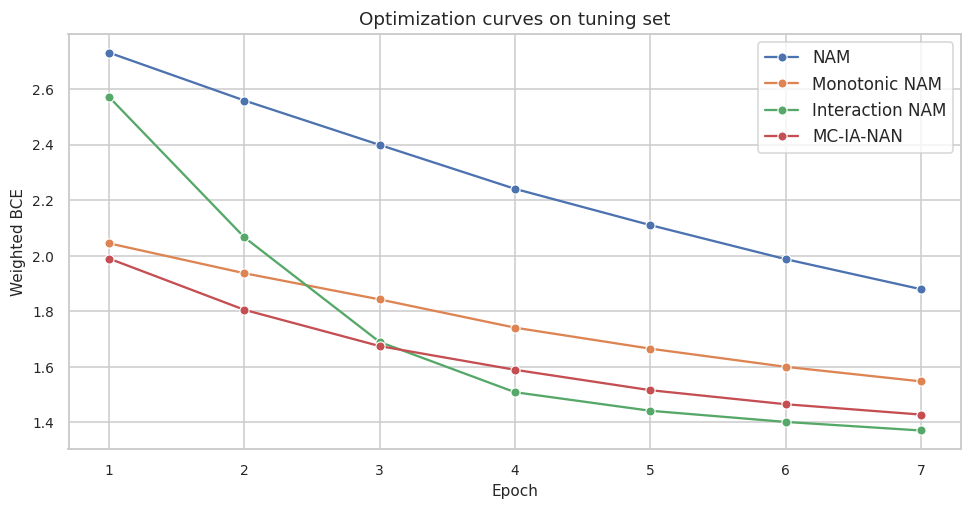

In [10]:
fig,ax=plt.subplots(figsize=(9,4.8))
for name,h in histories.items():sns.lineplot(x=h.epoch,y=h.tune_weighted_loss,label=name,ax=ax,marker='o')
ax.set(title='Optimization curves on tuning set',xlabel='Epoch',ylabel='Weighted BCE');tidy_x(ax);savefig('07_training_curves.png')


## 6. MC dropout and held-out probability calibration

In [11]:
final_model=models['MC-IA-NAN']
def mc_inference(model,ids,passes=12):
    # Only dropout layers remain stochastic; embedding and linear layers run as normal.
    model.eval()
    for m in model.modules():
        if isinstance(m,nn.Dropout):m.train()
    predictions=[]
    with torch.no_grad():
        for _ in range(passes):
            z=[]
            for xn,xc,_ in loader(ids,2048):z.append(torch.sigmoid(model(xn.to(DEVICE),xc.to(DEVICE))).cpu().numpy())
            predictions.append(np.concatenate(z))
    model.eval();samples=np.stack(predictions)
    return samples.mean(0),samples.var(0),samples
p_cal_mc,u_cal_mc,_=mc_inference(final_model,cal_idx,passes=12)
p_test_mc,u_test_mc,mc_samples=mc_inference(final_model,test_idx,passes=12)
# Calibrate the MC-averaged probabilities (temperature applied to their logits).
def apply_temperature(prob,temp):return expit(logit(np.clip(prob,1e-6,1-1e-6))/temp)
res=minimize_scalar(lambda t:log_loss(y[cal_idx],apply_temperature(p_cal_mc,t),labels=[0,1]),bounds=(.1,10),method='bounded')
TEMPERATURE=float(res.x)
p_test_cal=apply_temperature(p_test_mc,TEMPERATURE)
print('Learned calibration temperature:',round(TEMPERATURE,4),'MC dropout test mean variance:',round(float(u_test_mc.mean()),7))


Learned calibration temperature: 3.5803 MC dropout test mean variance: 0.0018708


## 7. Held-out test performance and architecture ablations

## 8. Calibration and uncertainty reliability

## 9. Global additive explanations and interaction effects

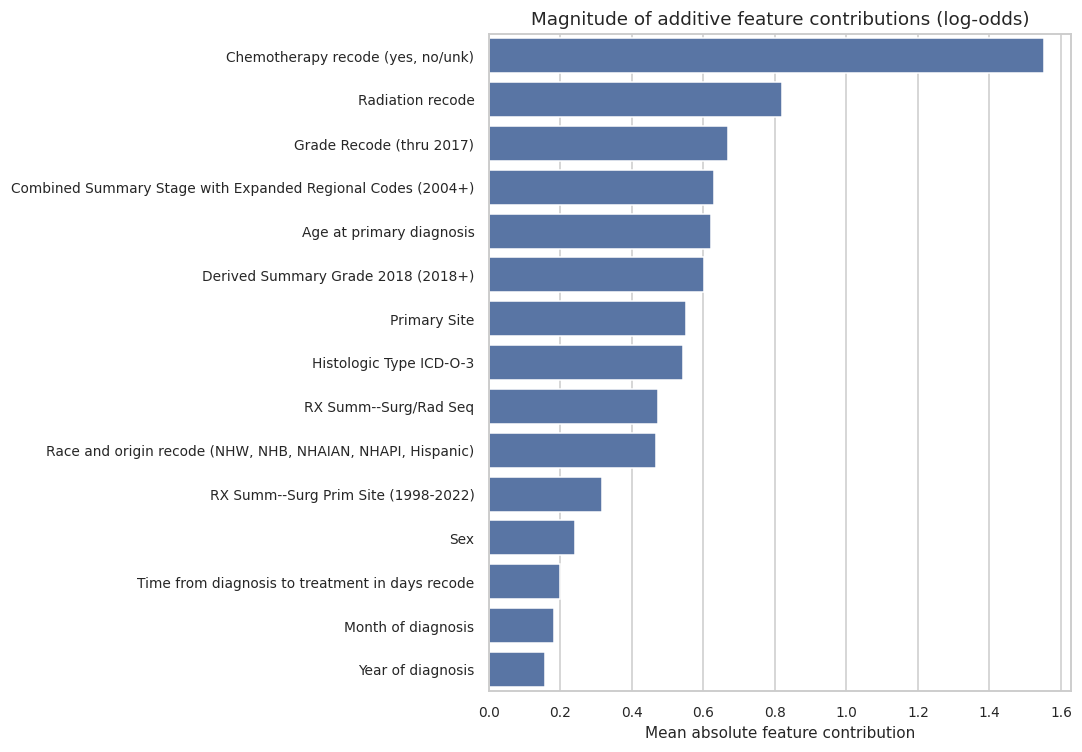

Age-monotonicity violation count over grid: 0


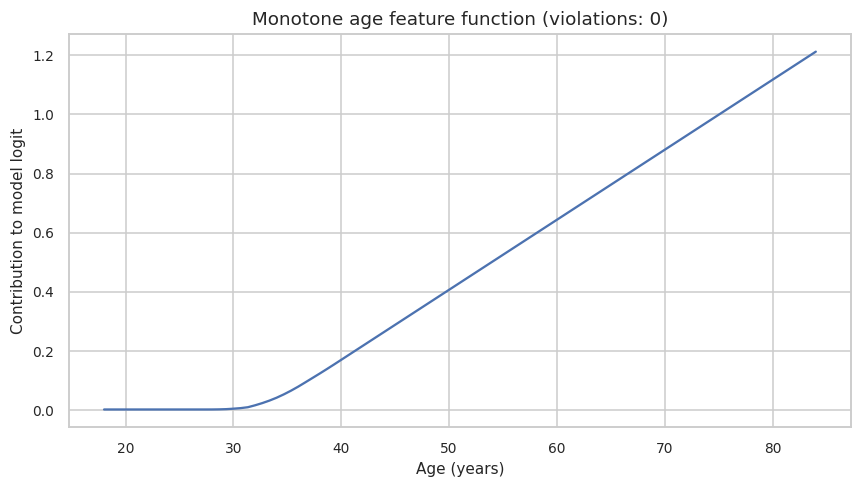

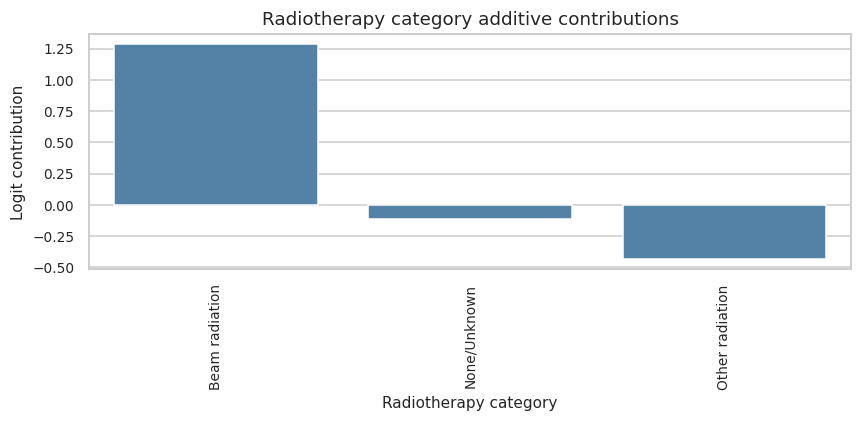

In [15]:
test_logits,feature_contrib,interaction_contrib=collect(final_model,test_idx,details=True)
feature_labels=NUM_COLS+CAT_COLS
importance=pd.DataFrame({'Feature':feature_labels,'Mean |logit contribution|':np.mean(np.abs(feature_contrib),axis=0)}).sort_values('Mean |logit contribution|',ascending=False)
fig,ax=plt.subplots(figsize=(10,7));sns.barplot(data=importance,y='Feature',x='Mean |logit contribution|',ax=ax,color=sns.color_palette()[0]);ax.set(title='Magnitude of additive feature contributions (log-odds)',xlabel='Mean absolute feature contribution',ylabel='');savefig('13_feature_contributions.png')
# Monotone shape vs observed age support; hold all other inputs irrelevant because each subnetwork is 1-D.
age_values=np.linspace(float(df['Age at primary diagnosis'].min()),float(df['Age at primary diagnosis'].max()),100).astype('float32')
age_scaled=((age_values-scaler.data_min_[0])/(scaler.data_max_[0]-scaler.data_min_[0])).astype("float32");final_model.eval()
with torch.no_grad():shape=final_model.numeric_units[0](torch.from_numpy(age_scaled[:,None]).to(DEVICE)).cpu().numpy().ravel()
violations=int(np.sum(np.diff(shape)<-1e-6));print('Age-monotonicity violation count over grid:',violations)
fig,ax=plt.subplots(figsize=(8,4.6));sns.lineplot(x=age_values,y=shape,ax=ax);ax.set(title=f'Monotone age feature function (violations: {violations})',xlabel='Age (years)',ylabel='Contribution to model logit');savefig('14_monotone_age_shape.png')
# Show categorical feature-specific shape function directly from embedding weights.
rad_col='Radiation recode';rad_idx=CAT_COLS.index(rad_col);vocab=category_maps[rad_col]
rad_import=pd.DataFrame({'Radiotherapy':list(vocab.keys()),'Logit contribution':[float(final_model.category_units[rad_idx].weight[k].detach().cpu().item()) for k in vocab.values()]})
fig,ax=plt.subplots(figsize=(8,4));sns.barplot(data=rad_import,x='Radiotherapy',y='Logit contribution',ax=ax,color='steelblue');ax.set(title='Radiotherapy category additive contributions',xlabel='Radiotherapy category',ylabel='Logit contribution');tidy_x(ax,long=True);savefig('15_radiotherapy_shape.png')


## 10. Patient-level decomposition and risk stratification

## 11. Decision curve and bootstrap confidence intervals